#### 04F · VAR a trozos: un VAR por régimen, régimen = clúster del estado anterior
Pruebas previas: gaussianizar PCs, n_harm = 2 y regímenes solo en el ruido (escala o media, K = 2–16) **no** recuperan la cola de f. Falta que la **dinámica** cambie según la situación.

Modelo (lineal a trozos, tipo SETAR con k-medias como frontera):
- PCs estandarizadas con `harm_std_pcs` (como producción) → Z.
- Régimen en t = **clúster k-medias de Z(t−1)**: definido por el estado anterior → estimación por mínimos cuadrados limpia (se selecciona por los predictores) y simulación coherente sin cadena de Markov.
- En cada régimen: VAR(p) con intercepto y Σ propios.

Comparación de la cola de f (XGB de producción) con el PVAR de producción y con un VAR único del mismo p (K = 1), para separar el efecto de los regímenes del de cambiar p.

In [2]:
import time, pickle, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

In [3]:
#### Configuración
point = "p102"
P = 2                                                       # retardos dentro de cada régimen
K_LIST = [1, 8, 16]                                         # 1 = VAR único (referencia del mismo p)
N_SIMS, N_ANOS = 4, 87
GUARDA_K, N_GUARDA = 8, 20                                  # ← N_GUARDA > 0 guarda simulaciones de ese K para el 08
burn = 4 * 365                                              # pasos de 6 h (1 año)

var_prod = pickle.load(open("outputs/var_6h/var_h1.pkl", "rb"))              # PVAR de producción (referencia)
harm_std_pcs = pickle.load(open("outputs/var_6h/harm_std_pcs.pkl", "rb"))
pcs = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True).loc["1941":"2025"]
xgb_final = XGBRegressor(); xgb_final.load_model(f"outputs/xgb_pit_{point}/xgb_final.json")
feat = json.load(open(f"outputs/xgb_pit_{point}/xgb_features.json"))
cols, lags = feat["columns"], feat["lags_h"]
print("PVAR producción: n_harm =", var_prod.n_harm, "| p =", var_prod.p)

PVAR producción: n_harm = 1 | p = 10


In [4]:
#### f del XGB (6 h) y "dirección de temporal" (como en el 08)
def con_lags(p):
    X = pd.concat({f"l{l}": p.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(p.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    return X.dropna()[cols]

def f_6h(p):
    X = con_lags(p)
    return pd.Series(xgb_final.predict(X), index=X.index)

X_h = con_lags(pcs)
f_hist = pd.Series(xgb_final.predict(X_h), index=X_h.index)
lr = LinearRegression().fit(X_h, f_hist)
w_dir = lr.coef_ / np.linalg.norm(lr.coef_); mu_dir = X_h.mean().values
dir_temp = lambda p: (con_lags(p).values - mu_dir) @ w_dir
s_h = dir_temp(pcs); sd_h = s_h.std()

def metricas(fs, ss):
    f = pd.concat(fs); s = np.concatenate(ss)
    return {"q90": f.quantile(0.9), "q99": f.quantile(0.99), "q99.9": f.quantile(0.999),
            "máx. anual": float(np.mean([x.groupby(x.index.year).max().mean() for x in fs])),
            "asim. dir. temporal": skew(s), "q99.9 dir. temporal (σ hist)": np.quantile(s, 0.999) / sd_h}

res = {"histórico": metricas([f_hist], [s_h])}
f_sims = {"histórico": [f_hist]}
Z = harm_std_pcs.transform(pcs); Zv = Z.values; k = Zv.shape[1]
fechas = pd.date_range("1940-01-01", periods=N_ANOS * 1461, freq="6h")
print(f"asimetría de la dirección de temporal (histórica): {skew(s_h):.2f}")

asimetría de la dirección de temporal (histórica): 0.33


#### 1. Referencia: PVAR de producción

In [5]:
t = time.time(); fs, ss = [], []
for i in range(N_SIMS):
    pc = harm_std_pcs.inverse_transform(var_prod.simulate(n_years=N_ANOS, start="1940-01-01", seed=i, burn=burn)).loc["1941":]
    fs.append(f_6h(pc)); ss.append(dir_temp(pc))
res["PVAR producción"] = metricas(fs, ss); f_sims["PVAR producción"] = fs
print(f"({time.time() - t:.0f} s)")

(10 s)


#### 2. VAR a trozos: ajuste por régimen

In [6]:
def ajusta(K):
    Y = Zv[P:]
    Xl = np.hstack([Zv[P - j - 1:len(Zv) - j - 1] for j in range(P)])        # [Z(t-1), …, Z(t-P)]
    if K == 1:
        km, lab = None, np.zeros(len(Y), int)
    else:
        km = KMeans(K, n_init=5, random_state=0).fit(Zv[::3])
        lab = km.predict(Zv[P - 1:-1])                                    # régimen en t = clúster de Z(t-1)
    mods = []
    for j in range(K):
        sel = lab == j
        A1 = np.c_[np.ones(sel.sum()), Xl[sel]]
        B, *_ = np.linalg.lstsq(A1, Y[sel], rcond=None)
        R = Y[sel] - A1 @ B
        S = np.cov(R.T) + 1e-6 * np.eye(k)
        comp = np.zeros((k * P, k * P)); comp[:k] = B[1:].T
        if P > 1: comp[k:, :-k] = np.eye(k * (P - 1))
        mods.append({"B": B, "L": np.linalg.cholesky(S), "radio": np.max(np.abs(np.linalg.eigvals(comp))),
                     "peso": sel.mean(), "escala": np.trace(S) / k})
    return km, mods, lab

def simula(km, mods, seed):
    rng = np.random.default_rng(seed); n = len(fechas) + burn
    y = np.zeros((n, k)); y[:P] = Zv[:P]; eps = rng.standard_normal((n, k)); explot = 0
    Cc = None if km is None else km.cluster_centers_
    reg = np.zeros(n, int)
    for t in range(P, n):
        j = 0 if Cc is None else int(np.argmin(((Cc - y[t - 1]) ** 2).sum(1)))
        reg[t] = j
        x = np.r_[1.0, y[t - P:t][::-1].ravel()]
        y[t] = x @ mods[j]["B"] + mods[j]["L"] @ eps[t]
        if not np.isfinite(y[t]).all() or np.abs(y[t]).max() > 50:      # salvaguarda (no debería saltar)
            explot += 1; y[t] = 0
    return pd.DataFrame(y[burn:], index=fechas, columns=Z.columns), explot, reg[burn:]

modelos = {}
for K in K_LIST:
    km, mods, lab = ajusta(K)
    modelos[K] = (km, mods, lab)
    print(f"K = {K}: radio espectral {np.round([m['radio'] for m in mods], 3)}")
    print(f"        peso {np.round([m['peso'] for m in mods], 3)} | escala de Σ {np.round([m['escala'] for m in mods], 2)}")

K = 1: radio espectral [0.955]
        peso [1.] | escala de Σ [0.16]
K = 8: radio espectral [0.956 0.953 0.943 0.94  0.963 0.959 0.963 0.934]
        peso [0.093 0.117 0.121 0.149 0.135 0.143 0.112 0.131] | escala de Σ [0.14 0.15 0.16 0.13 0.14 0.13 0.17 0.15]
K = 16: radio espectral [0.96  0.954 0.964 0.958 0.956 0.979 0.945 0.953 0.956 0.961 0.967 0.977
 0.976 0.949 0.945 0.959]
        peso [0.067 0.073 0.055 0.055 0.055 0.074 0.074 0.072 0.068 0.061 0.05  0.051
 0.059 0.05  0.076 0.061] | escala de Σ [0.13 0.12 0.14 0.15 0.16 0.15 0.12 0.13 0.15 0.14 0.14 0.14 0.15 0.17
 0.15 0.16]


#### 3. Simulación y cola de f

In [7]:
for K in K_LIST:
    t = time.time(); km, mods, _ = modelos[K]; fs, ss = [], []
    for i in range(N_SIMS):
        zsim, ex, _ = simula(km, mods, i)
        pc = harm_std_pcs.inverse_transform(zsim).loc["1941":]
        fs.append(f_6h(pc)); ss.append(dir_temp(pc))
        if ex: print(f"  K = {K}, sim {i}: {ex} pasos explosivos recortados")
    nom = f"VAR p={P} único" if K == 1 else f"VAR a trozos p={P}, K={K}"
    res[nom] = metricas(fs, ss); f_sims[nom] = fs
    print(f"{nom} ({time.time() - t:.0f} s)", flush=True)
display(pd.DataFrame(res).T.round(3))

VAR p=2 único (7 s)
VAR a trozos p=2, K=8 (9 s)
VAR a trozos p=2, K=16 (9 s)


,q90,q99,q99.9,máx. anual,asim. dir. temporal,q99.9 dir. temporal (σ hist)
histórico,0.966,1.941,2.681,2.673,0.333,3.863
PVAR producción,0.839,1.726,2.423,2.356,0.099,3.547
VAR p=2 único,0.819,1.666,2.338,2.292,0.099,3.495
"VAR a trozos p=2, K=8",0.857,1.813,2.508,2.470,0.051,3.482
"VAR a trozos p=2, K=16",0.862,1.799,2.508,2.465,0.031,3.485


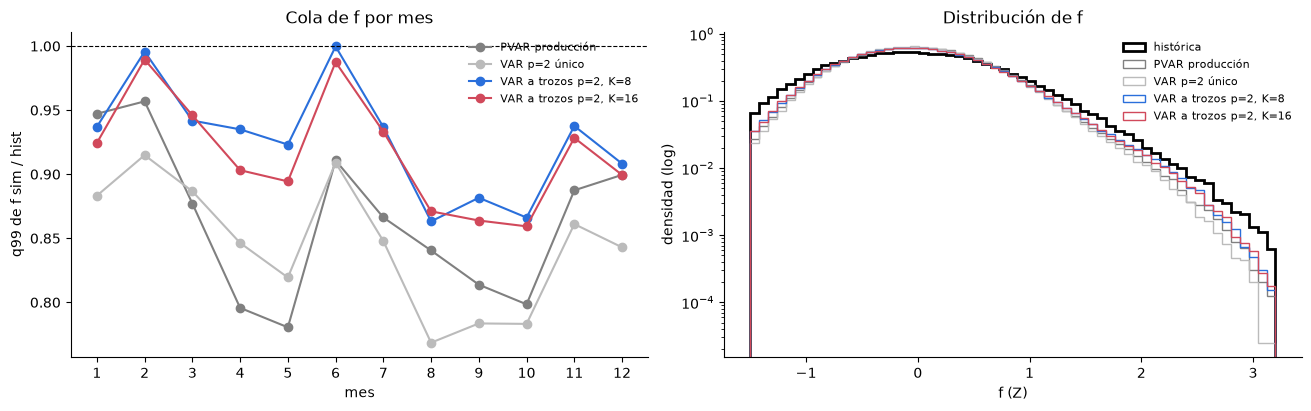

In [8]:
#### q99 de f por mes (ratio sim/hist) y distribución de la dirección de temporal
q99_h = f_hist.groupby(f_hist.index.month).quantile(0.99)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
paleta = ["0.5", "#bbbbbb", "#2a6fdb", "#d1495b", "#3a9e5f"]
for (nom, fs), col in zip([(n_, v_) for n_, v_ in f_sims.items() if n_ != "histórico"], paleta):
    f_ = pd.concat(fs); r = f_.groupby(f_.index.month).quantile(0.99) / q99_h
    ax[0].plot(r.index, r.values, "o-", color=col, label=nom)
ax[0].axhline(1, color="k", lw=0.8, ls="--")
ax[0].set(xlabel="mes", ylabel="q99 de f sim / hist", xticks=range(1, 13), title="Cola de f por mes")
ax[0].legend(frameon=False, fontsize=8)
b = np.linspace(-1.5, 3.2, 60)
ax[1].hist(f_hist, bins=b, density=True, histtype="step", color="k", lw=2, label="histórica", log=True)
for (nom, fs), col in zip([(n_, v_) for n_, v_ in f_sims.items() if n_ != "histórico"], paleta):
    ax[1].hist(pd.concat(fs), bins=b, density=True, histtype="step", color=col, label=nom, log=True)
ax[1].set(xlabel="f (Z)", ylabel="densidad (log)", title="Distribución de f")
ax[1].legend(frameon=False, fontsize=8)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.show()

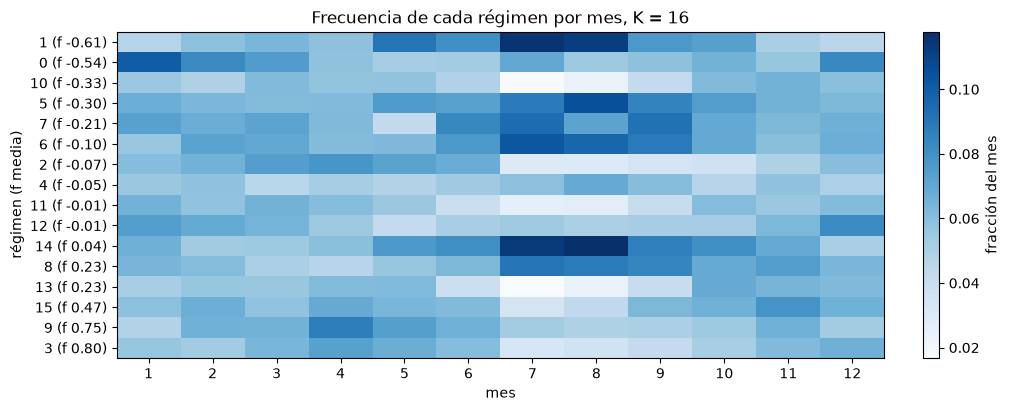

In [9]:
#### ¿Tienen los regímenes estacionalidad? Frecuencia de cada régimen por mes (histórico, K mayor)
K_ = max(K_LIST); lab = pd.Series(modelos[K_][2], index=Z.index[P:])
fr = lab.groupby(lab.index.month).value_counts(normalize=True).unstack().fillna(0)
f_reg = pd.Series(f_hist.reindex(lab.index).values, index=lab.index).groupby(lab.values).mean()
orden = f_reg.sort_values().index                                          # regímenes ordenados por f media
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
im = ax.imshow(fr[orden].T.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(K_), [f"{j} (f {f_reg[j]:.2f})" for j in orden])
ax.set(xlabel="mes", ylabel="régimen (f media)", title=f"Frecuencia de cada régimen por mes, K = {K_}")
fig.colorbar(im, ax=ax, label="fracción del mes")
plt.show()

#### 4. (Opcional) Guardar simulaciones del modelo elegido para el 08

In [10]:
if N_GUARDA > 0:
    carpeta = f"outputs/var_trozos_K{GUARDA_K}/simulaciones"
    os.makedirs(carpeta, exist_ok=True)
    km, mods, _ = modelos[GUARDA_K]
    for i in range(N_GUARDA):
        zsim, ex, _ = simula(km, mods, 1000 + i)
        harm_std_pcs.inverse_transform(zsim).astype("float32").to_parquet(f"{carpeta}/sim_{i:03d}.parquet")
        print(f"sim {i:03d} guardada" + (f" ({ex} pasos recortados)" if ex else ""), flush=True)
    print(f"En el 08: glob('{carpeta}/sim_*.parquet') y un SUF nuevo")

sim 000 guardada
sim 001 guardada
sim 002 guardada
sim 003 guardada
sim 004 guardada
sim 005 guardada
sim 006 guardada
sim 007 guardada
sim 008 guardada
sim 009 guardada
sim 010 guardada
sim 011 guardada
sim 012 guardada
sim 013 guardada
sim 014 guardada
sim 015 guardada
sim 016 guardada
sim 017 guardada
sim 018 guardada
sim 019 guardada
En el 08: glob('outputs/var_trozos_K8/simulaciones/sim_*.parquet') y un SUF nuevo


corr(f, s) = 0.71  (s es una buena aproximación lineal de f si es alta)


,s(t−1) medio,media choque,std choque,asimetría choque
decil de s(t−1),,,,
0,-1.709,-0.005,0.205,0.251
1,-1.063,-0.001,0.206,0.333
2,-0.711,0.000,0.205,0.214
3,-0.427,0.003,0.210,0.192
4,-0.168,0.003,0.211,0.125
5,0.086,0.002,0.216,0.098
6,0.356,0.000,0.221,0.125
7,0.667,0.000,0.229,-0.057
8,1.070,-0.001,0.242,-0.034


e²  ≈ 0.046 + +0.009·s + +0.004·s²   (pendiente > 0: más ruido cuando ya hay temporal)
e   ≈ 0.001 + +0.000·s + -0.001·s²   (término s² ≠ 0: empujón con signo → asimetría)
estado s (histórico)   S = +0.28 | K = +0.21 | 1.5·S² = 0.12 → compatible con CAM
choque e_s             S = +0.05 | K = +1.29 | 1.5·S² = 0.00 → compatible con CAM
            std choque (s alto)  std choque (resto)  asim. choque (s alto)
invierno                  0.287               0.230                 -0.405
transición                0.286               0.213                 -0.145
verano                    0.245               0.203                 -0.161


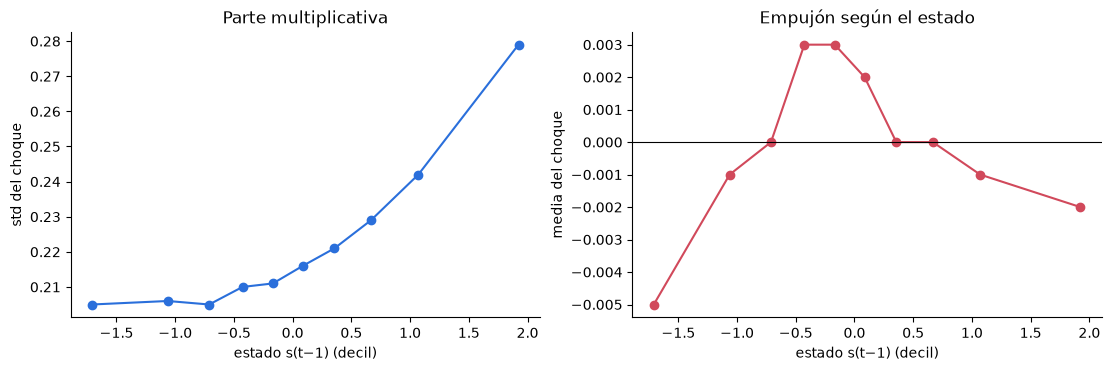

In [11]:
#### Diagnóstico CAM: ¿el ruido del PVAR depende del estado (multiplicativo) y está correlacionado con él (asimetría)?
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression

#### Dirección de temporal en el espacio del PVAR: proyección de Z(t) que mejor explica f(t)
fz = f_hist.reindex(Z.index).dropna()
w_s = LinearRegression().fit(Z.loc[fz.index], fz).coef_
w_s = w_s / np.linalg.norm(w_s)
s = pd.Series(Z.values @ w_s, index=Z.index)                       # estado en la dirección de temporal
e = var_prod.resid_                                                 # innovaciones del PVAR (espacio Z)
e_s = pd.Series(e[Z.columns].values @ w_s, index=e.index)           # choque en la dirección de temporal
s_prev = s.shift(1).reindex(e_s.index)                              # estado en t−1
ok = s_prev.notna()
e_s, s_prev = e_s[ok], s_prev[ok]
print(f"corr(f, s) = {np.corrcoef(fz, s.loc[fz.index])[0, 1]:.2f}  (s es una buena aproximación lineal de f si es alta)")

#### 1. Momentos del choque por decil del estado anterior
dec = pd.qcut(s_prev, 10, labels=False)
tab = pd.DataFrame({"s(t−1) medio": s_prev.groupby(dec).mean(),
                    "media choque": e_s.groupby(dec).mean(),
                    "std choque": e_s.groupby(dec).std(),
                    "asimetría choque": e_s.groupby(dec).apply(skew)}).round(3)
tab.index.name = "decil de s(t−1)"
display(tab)

#### 2. Regresiones: e² ~ s(t−1) (parte multiplicativa) y e ~ s(t−1)² (correlación aditiva-multiplicativa)
X1 = np.c_[s_prev.values, s_prev.values ** 2]
r_var = LinearRegression().fit(X1, e_s.values ** 2)
r_med = LinearRegression().fit(X1, e_s.values)
print(f"e²  ≈ {r_var.intercept_:.3f} + {r_var.coef_[0]:+.3f}·s + {r_var.coef_[1]:+.3f}·s²   (pendiente > 0: más ruido cuando ya hay temporal)")
print(f"e   ≈ {r_med.intercept_:.3f} + {r_med.coef_[0]:+.3f}·s + {r_med.coef_[1]:+.3f}·s²   (término s² ≠ 0: empujón con signo → asimetría)")

#### 3. Asimetría/curtosis y cota CAM (K ≥ 1.5·S²)
for nom, x in [("estado s (histórico)", s), ("choque e_s", e_s)]:
    S_, K_ = skew(x), kurtosis(x)
    print(f"{nom:22s} S = {S_:+.2f} | K = {K_:+.2f} | 1.5·S² = {1.5 * S_ ** 2:.2f} → {'compatible' if K_ >= 1.5 * S_ ** 2 else 'NO compatible'} con CAM")

#### 4. Por estación (std del choque en el 10 % más alto de s(t−1) frente al resto)
est_ = lambda ix: np.where(ix.month.isin([11, 12, 1, 2]), "invierno", np.where(ix.month.isin([3, 4, 5, 9, 10]), "transición", "verano"))
alto = s_prev > s_prev.quantile(0.9)
print(pd.DataFrame({"std choque (s alto)": e_s[alto].groupby(est_(e_s[alto].index)).std(),
                    "std choque (resto)": e_s[~alto].groupby(est_(e_s[~alto].index)).std(),
                    "asim. choque (s alto)": e_s[alto].groupby(est_(e_s[alto].index)).apply(skew)}).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
ax[0].plot(tab["s(t−1) medio"], tab["std choque"], "o-", color="#2a6fdb")
ax[0].set(xlabel="estado s(t−1) (decil)", ylabel="std del choque", title="Parte multiplicativa")
ax[1].plot(tab["s(t−1) medio"], tab["media choque"], "o-", color="#d1495b"); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xlabel="estado s(t−1) (decil)", ylabel="media del choque", title="Empujón según el estado")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.show()

#### Cómo leerlo
- **K = 1 vs K = 8/16 (mismo p)** = efecto de los regímenes. **vs PVAR producción** = lo que ganarías cambiando el generador.
- Objetivo: f q99 1.94, q99.9 2.68, máx. anual 2.67; cola por mes hacia 1, sobre todo mar–may y sep–nov.
- Radio espectral < 1 en cada régimen y ningún paso explosivo: modelo estable.
- Mapa de regímenes por mes: si los regímenes de f alta son más frecuentes en invierno/transición, los regímenes recogen física (y la estacionalidad) sin coeficientes periódicos.
- Pendiente si funciona: Σ estacional dentro de cada régimen, p mayor con regularización, y la cadena completa (08 + 09B) con N_GUARDA > 0.